# Numerical Wave Tank — Visualisation Demo

This notebook exercises every function in `src/visualise.py` using a single JONSWAP irregular sea state.

| Function | What it shows |
|---|---|
| `plot_spectrum` | JONSWAP target S(f) vs empirical spectrum from generated amplitudes |
| `snapshot_time` | Spatial profile η(x) frozen at a chosen instant |
| `snapshot_space` | Time series η(t) recorded at a fixed gauge location |
| `animate_surface` | Full animation of the wave field travelling past; exported as a GIF |

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from wave_tank import IrregularWave_JONSWAP, RegularWave
from visualise import plot_spectrum, snapshot_time, snapshot_space, animate_surface, animate_particles

## Sea state

A typical North Sea storm in 50 m of water:

| Parameter | Value |
|---|---|
| Hs | 3.5 m |
| Tp | 12 s |
| depth d | 50 m |
| γ (JONSWAP) | 3.3 |

The peak wavelength in 50 m of water is roughly 170 m, so the wave is in the intermediate-depth regime.

In [2]:
storm = IrregularWave_JONSWAP(Hs=3.5, Tp=12.0, d=50.0, gamma=3.3, seed=42)
print(storm)
print(f"Number of components : {len(storm.f)}")
print(f"Frequency resolution : {storm.f[1]-storm.f[0]:.5f} Hz  (df = 1/T_repeat)")
print(f"Target Hs            : {storm.Hs:.3f} m")
print(f"Actual Hs            : {storm.actual_hs:.3f} m  (4·√m₀ from generated amplitudes)")

IrregularWave_JONSWAP(Hs=3.5m, Tp=12.0s, d=50.0m, gamma=3.3, N=4050 components, actual_hs=3.569m)
Number of components : 4050
Frequency resolution : 0.00009 Hz  (df = 1/T_repeat)
Target Hs            : 3.500 m
Actual Hs            : 3.569 m  (4·√m₀ from generated amplitudes)


## 1. Energy Spectrum — `plot_spectrum`

The red curve is the theoretical JONSWAP target $S(f)$ used to set the Rayleigh scale parameters.
The blue fill is the empirical spectrum estimated from the actual drawn amplitudes:
$$S_{\mathrm{emp}}(f_i) = \frac{a_i^2}{2\,\Delta f}$$

Because amplitudes are Rayleigh-distributed (not fixed), the empirical spectrum scatters around the
target — matching the variability seen in real wave-buoy records.

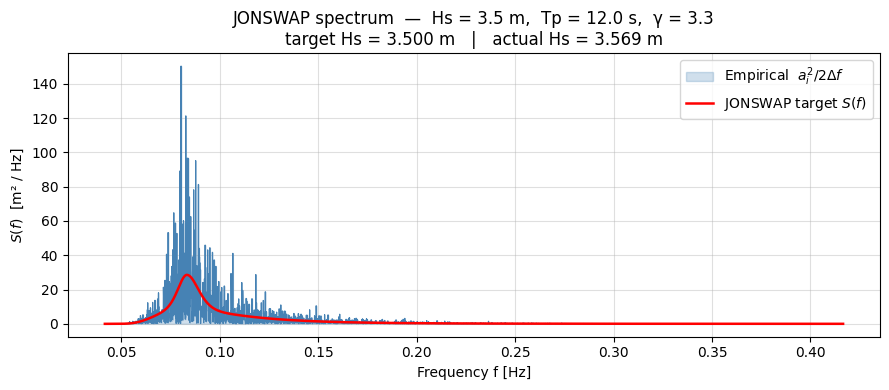

In [3]:
fig, ax = plot_spectrum(storm)
plt.show()

## 2. Spatial Snapshot — `snapshot_time`

A photograph of the wave field across the tank at a single instant.
600 m covers roughly 3–4 peak wavelengths so wave groups are clearly visible.

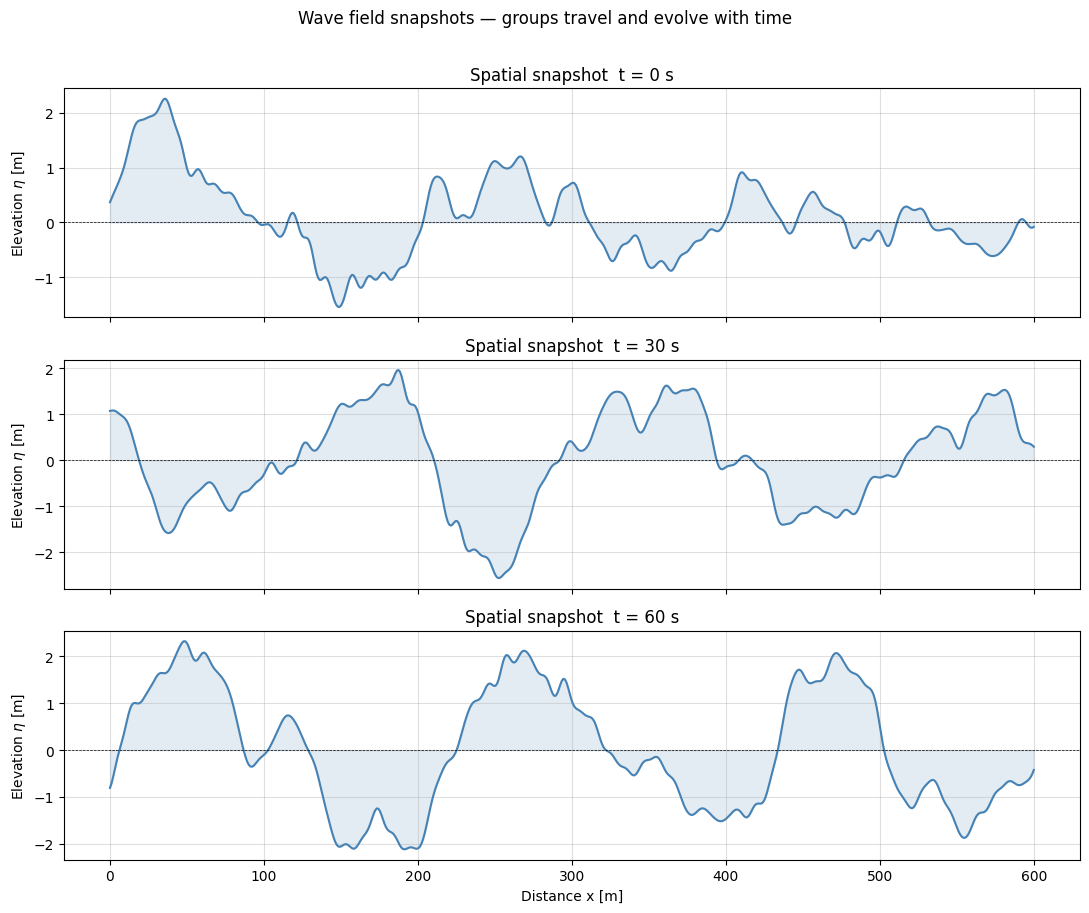

In [4]:
x = np.linspace(0, 600, 600)   # 600 m tank, 1 m resolution

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for ax, t_snap in zip(axes, [0.0, 30.0, 60.0]):
    snapshot_time(storm, x, t=t_snap, ax=ax)
    ax.set_title(f"Spatial snapshot  t = {t_snap:.0f} s")

axes[0].set_xlabel("")   # suppress duplicate x-labels on top panels
axes[1].set_xlabel("")
fig.suptitle("Wave field snapshots — groups travel and evolve with time", y=1.01)
plt.tight_layout()
plt.show()

## 3. Time Series — `snapshot_space`

What a wave gauge records at a fixed location.
Three gauges are placed along the tank to illustrate how the same groups arrive at different times.

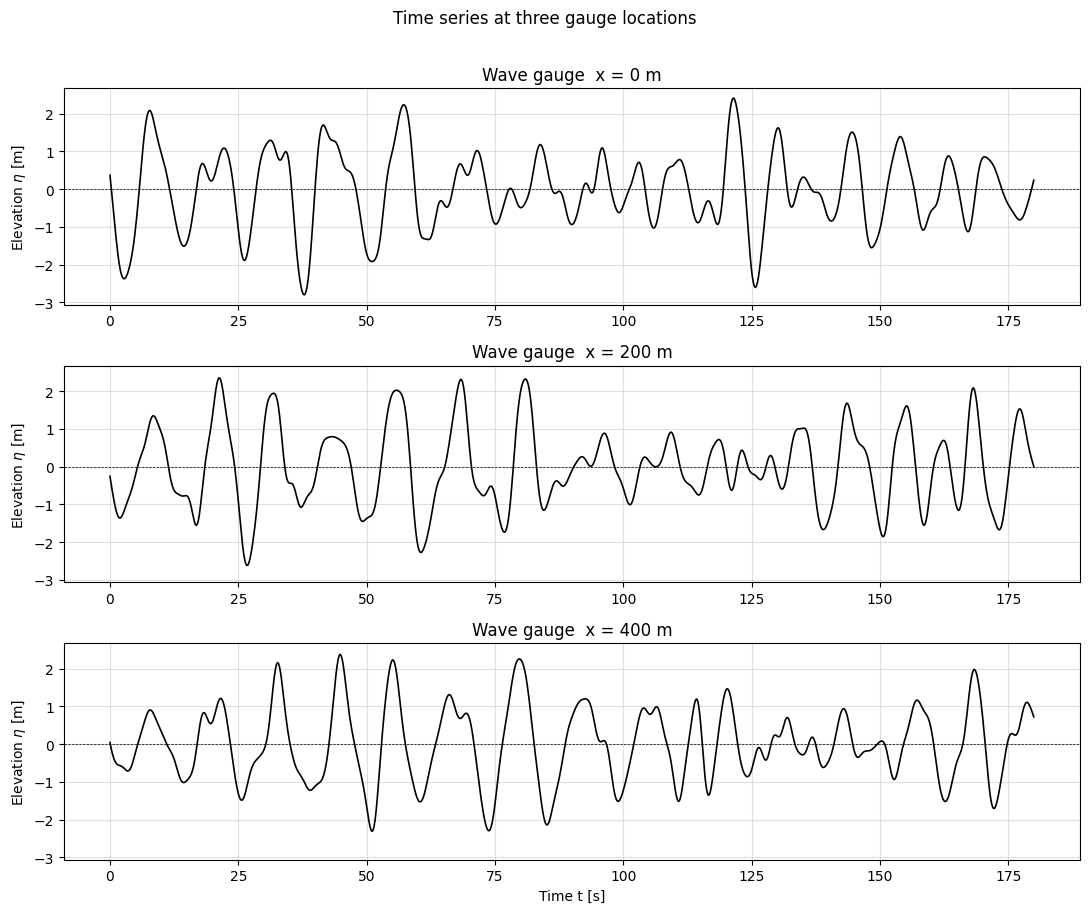

In [5]:
t = np.linspace(0, 180, 900)   # 3 minutes at 0.2 s resolution

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharey=True)

for ax, x_gauge in zip(axes, [0.0, 200.0, 400.0]):
    snapshot_space(storm, t, x=x_gauge, ax=ax)
    ax.set_title(f"Wave gauge  x = {x_gauge:.0f} m")

axes[0].set_xlabel("")   # suppress duplicate x-labels
axes[1].set_xlabel("")
fig.suptitle("Time series at three gauge locations", y=1.01)
plt.tight_layout()
plt.show()

## 4. Animation — `animate_surface`

The animation frames are pre-computed and exported to `output/storm_animation.gif`.
Running the next cell can take 10–20 s depending on hardware.

The `IPython.display.Image` call below embeds the saved GIF directly in the notebook so it plays
without needing a live matplotlib window.

In [6]:
x_anim = np.linspace(0, 600, 500)        # spatial domain
t_anim = np.linspace(0, 60, 120)         # 60 s, 2 fps × 60 = 120 frames at 20 fps → 6 s loop

ani = animate_surface(
    storm,
    x_anim,
    t_anim,
    fps=20,
    save_path="output/storm_animation.gif",
)
plt.close()   # prevent a static duplicate from appearing below the GIF

Saved: output/storm_animation.gif


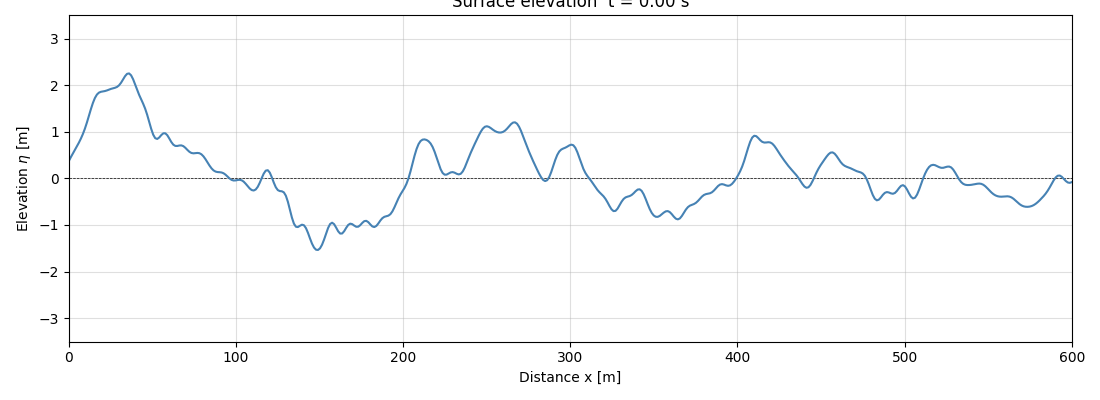

In [7]:
from IPython.display import Image
Image("output/storm_animation.gif")

## 5. Particle Orbit Animation — `animate_particles`

Airy wave theory predicts that water particles trace **closed ellipses** whose
shape changes with depth:

| Depth | Horizontal semi-axis A(z) | Vertical semi-axis B(z) |
|---|---|---|
| Surface (z = 0) | largest | largest |
| Mid-depth | smaller | smaller |
| Seabed (z = −d) | non-zero (some surge) | **zero** (no heave) |

For intermediate/deep water the surface orbits are nearly circular; in shallow
water they become strongly flattened (large A, tiny B at all depths).

**Orbit direction:** clockwise — under the wave crest the particle is at the
*top* of its ellipse, moving in the direction of wave propagation.

The `exaggeration` parameter scales the orbital radii for visual clarity without
altering the wave height or depth axes.

In [8]:
wave = RegularWave(H=2.0, T=8.0, d=10.0)
print(wave)
print(f'Wavelength λ = {wave.L:.1f} m   |   wave regime: {wave.regime}')

# Four particle columns evenly spaced over one wavelength
x_positions = np.linspace(0, wave.L, 5)[:-1]      # 0, λ/4, λ/2, 3λ/4

# Five depth levels from free surface to seabed
z_levels = np.linspace(0, -wave.d, 5)             # 0, -d/4, ..., -d

print(f'x_positions: {np.round(x_positions, 1)} m')
print(f'z_levels:    {np.round(z_levels, 1)} m')

RegularWave(H=2.0m, T=8.0s, d=10.0m, L=70.90m, C=8.86m/s, Cg=7.18m/s, regime='intermediate')
Wavelength λ = 70.9 m   |   wave regime: intermediate
x_positions: [ 0.  17.7 35.4 53.2] m
z_levels:    [  0.   -2.5  -5.   -7.5 -10. ] m


In [9]:
ani = animate_particles(
    wave,
    x_positions=x_positions,
    z_levels=z_levels,
    fps=20,
    n_cycles=2,
    exaggeration=1.0,   # enlarge orbits ×5 so they are clearly visible
    save_path='output/particle_orbits.gif',
)
plt.close()

Saved: output/particle_orbits.gif


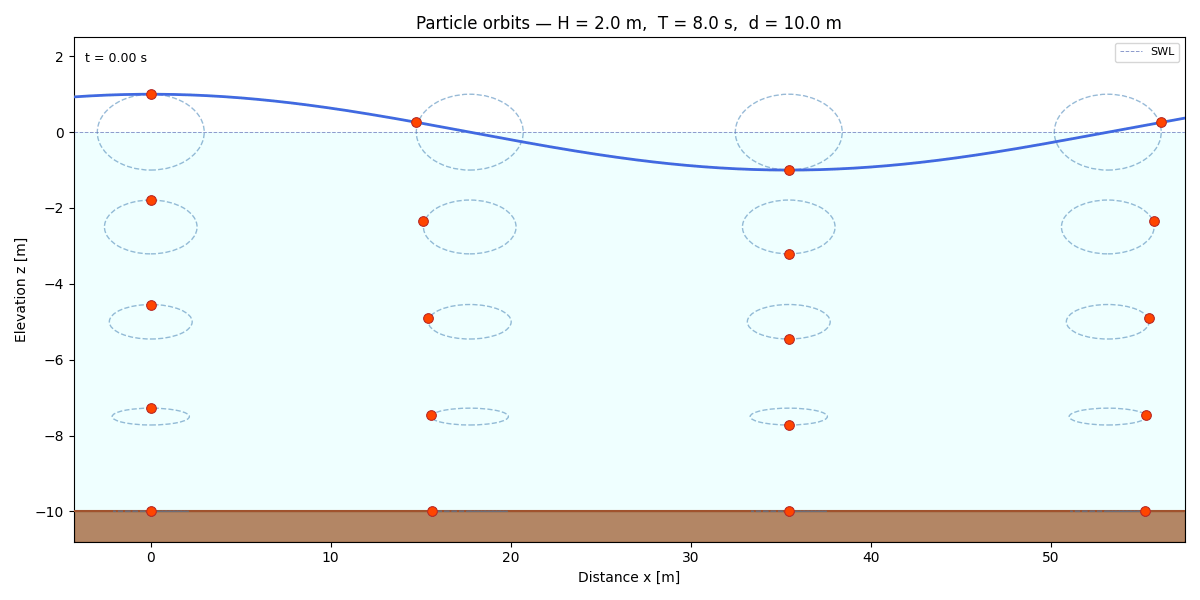

In [10]:
from IPython.display import Image
Image('output/particle_orbits.gif')